# 02 Performance analysis: momentum vs 60/40

Goes beyond the headline statistics in `01_backtest.ipynb`:

1. **Risk-adjusted and relative performance.** Sortino, tracking error, information ratio, beta.
2. **Calendar-year returns.** In which years did momentum win or lose against the 60/40?
3. **Consistency over time.** Is the relative performance stable, or concentrated in a few periods (rolling 36-month view)?

Run the cells from top to bottom. Charts are saved to `reports/figures/`.

In [1]:
# Run once if yfinance is not installed yet (then restart the kernel):
# %pip install -q yfinance

In [2]:
import sys
sys.path.insert(0, "..")   # lets the notebook find the src/ folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.backtest import *

FIGURES = "../reports/figures"

## 1. Run the backtest

In [3]:
res = run_comparison()
strategy, bench = res["strategy"], res["bench"]

Loaded 262 months of real data (2005-01 to 2026-10)
Period: 2006-03-31 to 2026-10-31 (248 months)


## 2. Extended performance metrics

| Metric | What it measures |
|---|---|
| **Sortino ratio** | Like Sharpe, but only penalises *downside* volatility (months below the risk-free rate) |
| **Best / worst month** | The extremes of the monthly return distribution |
| **Active return** | Average annual return difference against the 60/40 (arithmetic) |
| **Tracking error** | Annualised volatility of that difference: how far the strategy strays from the benchmark |
| **Information ratio** | Active return ÷ tracking error: reward per unit of deviation from the benchmark |
| **Beta** | Sensitivity to the 60/40: 1.0 means it moves one-for-one with the benchmark |
| **Correlation** | How closely monthly returns move together |

In [4]:
def extended_stats(r, rf_annual=RISK_FREE_ANNUAL):
    """Absolute risk and return statistics for one monthly return series."""
    r = r.dropna()
    years = len(r) / 12
    cagr = (1 + r).prod() ** (1 / years) - 1
    vol = r.std() * np.sqrt(12)

    rf_m = (1 + rf_annual) ** (1 / 12) - 1
    downside = np.minimum(r - rf_m, 0)
    downside_dev = np.sqrt((downside ** 2).mean()) * np.sqrt(12)

    max_dd = drawdown_series(r).min()
    return {
        "CAGR": cagr,
        "Volatility": vol,
        "Sharpe ratio": (cagr - rf_annual) / vol,
        "Sortino ratio": (cagr - rf_annual) / downside_dev,
        "Max drawdown": max_dd,
        "Calmar ratio": cagr / abs(max_dd),
        "Best month": r.max(),
        "Worst month": r.min(),
    }


def relative_stats(r, b):
    """Statistics of the strategy measured against the benchmark."""
    active = r - b
    active_return = active.mean() * 12
    tracking_error = active.std() * np.sqrt(12)
    beta = np.cov(r, b)[0, 1] / b.var()
    return {
        "Active return": active_return,
        "Tracking error": tracking_error,
        "Information ratio": active_return / tracking_error,
        "Beta to 60/40": beta,
        "Correlation with 60/40": r.corr(b),
        "Months beating 60/40": (active > 0).mean(),
    }


pct = lambda x: f"{x:.2%}"
num = lambda x: f"{x:.2f}"
formats = {
    "CAGR": pct, "Volatility": pct, "Sharpe ratio": num, "Sortino ratio": num,
    "Max drawdown": pct, "Calmar ratio": num, "Best month": pct, "Worst month": pct,
    "Active return": pct, "Tracking error": pct, "Information ratio": num,
    "Beta to 60/40": num, "Correlation with 60/40": num, "Months beating 60/40": pct,
}

absolute = pd.DataFrame({
    "Momentum": extended_stats(strategy),
    "60/40": extended_stats(bench),
})
relative = pd.Series(relative_stats(strategy, bench), name="Momentum vs 60/40")

print("Absolute statistics")
print(absolute.apply(lambda col: [formats[k](v) for k, v in col.items()]).to_string())
print("\nRelative to the 60/40")
print(pd.Series({k: formats[k](v) for k, v in relative.items()}).to_string())

Absolute statistics
              Momentum    60/40
CAGR             7.92%    8.16%
Volatility      11.99%    9.25%
Sharpe ratio      0.49     0.67
Sortino ratio     0.79     1.00
Max drawdown   -19.13%  -29.46%
Calmar ratio      0.41     0.28
Best month      11.56%    7.73%
Worst month     -9.68%  -10.26%

Relative to the 60/40
Active return              0.06%
Tracking error             9.87%
Information ratio           0.01
Beta to 60/40               0.77
Correlation with 60/40      0.59
Months beating 60/40      48.79%


## 3. Calendar-year returns

The first and last years are partial (the test starts in March 2006 and ends with the latest month of data); they are marked with `*`.

In [5]:
yearly = pd.DataFrame({
    "Momentum": (1 + strategy).groupby(strategy.index.year).prod() - 1,
    "60/40": (1 + bench).groupby(bench.index.year).prod() - 1,
})
yearly["Difference"] = yearly["Momentum"] - yearly["60/40"]

months_per_year = strategy.groupby(strategy.index.year).size()
yearly.index = [f"{y}*" if months_per_year[y] < 12 else str(y) for y in yearly.index]

print(yearly.map(lambda x: f"{x:7.1%}").to_string())
full = yearly[~yearly.index.str.endswith("*")]
print(f"\nFull years momentum beat 60/40: {(full['Difference'] > 0).sum()} of {len(full)}")

      Momentum    60/40 Difference
2006*    13.5%     8.8%       4.7%
2007     12.3%     7.4%       4.9%
2008      7.0%   -18.0%      25.0%
2009      2.7%    12.6%      -9.9%
2010      9.7%    13.5%      -3.8%
2011     -4.1%     7.7%     -11.8%
2012      4.9%    11.2%      -6.2%
2013     16.7%    15.6%       1.1%
2014     15.3%    11.8%       3.5%
2015     -1.4%     1.7%      -3.1%
2016     -6.1%     7.7%     -13.8%
2017     26.3%    13.7%      12.5%
2018     -6.7%    -2.0%      -4.7%
2019     22.7%    21.8%       0.9%
2020      5.2%    16.0%     -10.8%
2021      8.7%    15.1%      -6.3%
2022    -16.4%   -16.7%       0.3%
2023     14.0%    16.8%      -2.7%
2024     18.5%    14.1%       4.4%
2025     30.5%    13.9%      16.6%
2026*     2.9%     6.4%      -3.4%

Full years momentum beat 60/40: 9 of 19


Chart saved to ../reports/figures/calendar_returns.png


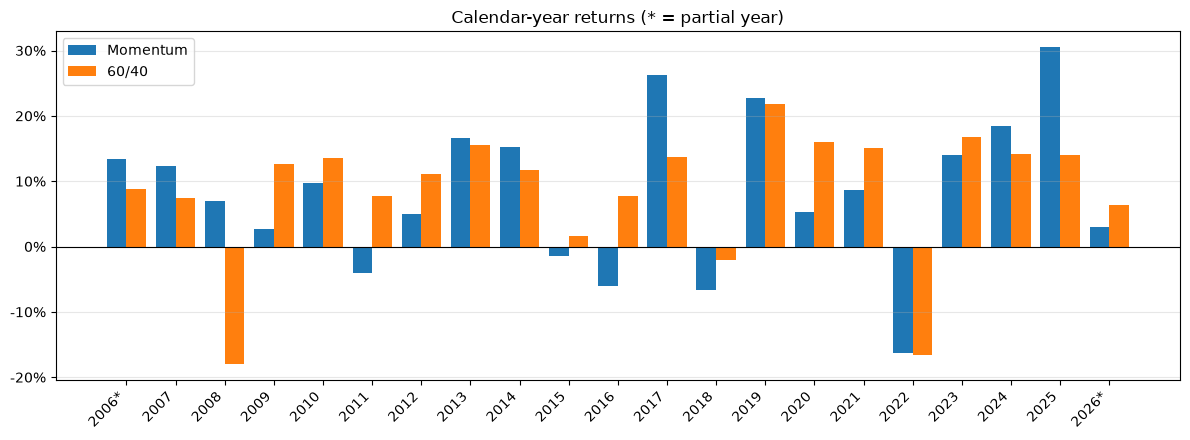

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(len(yearly))
ax.bar(x - 0.2, yearly["Momentum"], width=0.4, label="Momentum")
ax.bar(x + 0.2, yearly["60/40"], width=0.4, label="60/40")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(yearly.index, rotation=45, ha="right")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Calendar-year returns (* = partial year)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
save_figure(fig, f"{FIGURES}/calendar_returns.png")
plt.show()

## 4. Rolling 36-month view

Each point shows the previous three years. If the strategy's edge were stable, the rolling active return would stay on one side of zero.

Chart saved to ../reports/figures/rolling_36m.png


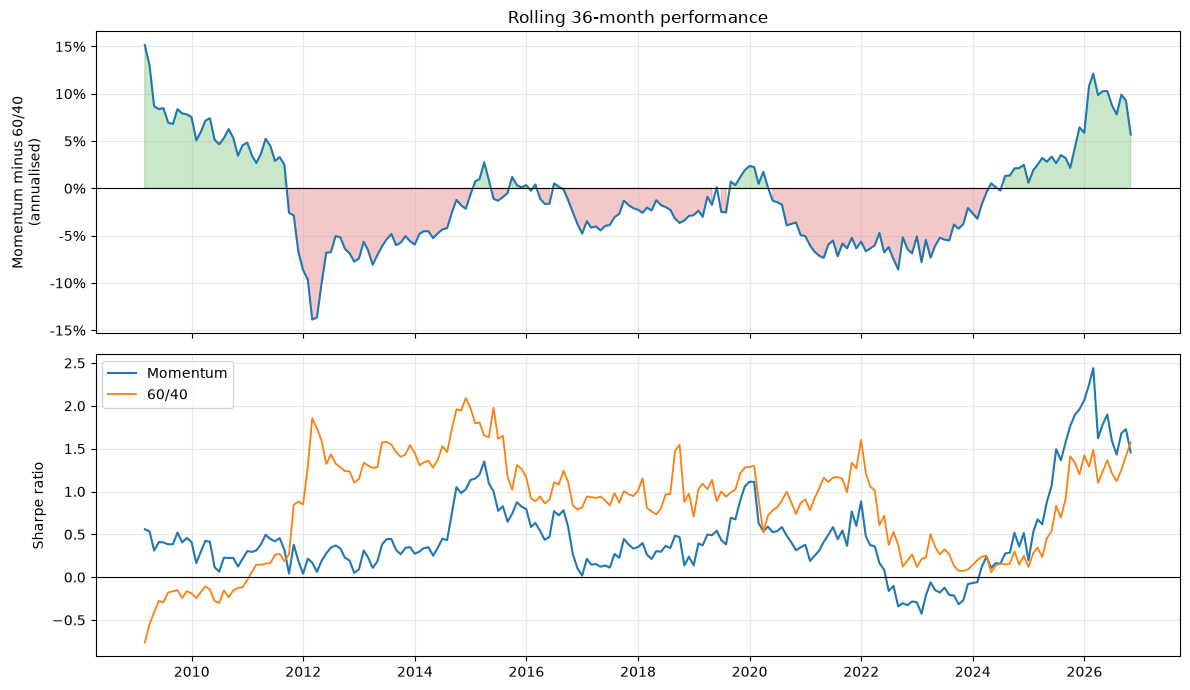

Share of 36-month windows where momentum beat 60/40: 38%


In [7]:
WINDOW = 36

def rolling_cagr(r, window=WINDOW):
    return (1 + r).rolling(window).apply(np.prod, raw=True) ** (12 / window) - 1

roll_active = rolling_cagr(strategy) - rolling_cagr(bench)
roll_sharpe_strat = (rolling_cagr(strategy) - RISK_FREE_ANNUAL) / (strategy.rolling(WINDOW).std() * np.sqrt(12))
roll_sharpe_bench = (rolling_cagr(bench) - RISK_FREE_ANNUAL) / (bench.rolling(WINDOW).std() * np.sqrt(12))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

ax1.plot(roll_active.index, roll_active, color="tab:blue", lw=1.5)
ax1.fill_between(roll_active.index, roll_active, 0, where=roll_active > 0, color="tab:green", alpha=0.25)
ax1.fill_between(roll_active.index, roll_active, 0, where=roll_active < 0, color="tab:red", alpha=0.25)
ax1.axhline(0, color="black", lw=0.8)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax1.set_ylabel("Momentum minus 60/40\n(annualised)")
ax1.set_title("Rolling 36-month performance")

ax2.plot(roll_sharpe_strat.index, roll_sharpe_strat, label="Momentum", lw=1.5)
ax2.plot(roll_sharpe_bench.index, roll_sharpe_bench, label="60/40", lw=1.3)
ax2.axhline(0, color="black", lw=0.8)
ax2.set_ylabel("Sharpe ratio")
ax2.legend()

for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
save_figure(fig, f"{FIGURES}/rolling_36m.png")
plt.show()

share_ahead = (roll_active.dropna() > 0).mean()
print(f"Share of 36-month windows where momentum beat 60/40: {share_ahead:.0%}")